<!-- m6:proyecto -->
# Módulo 6 · Proyecto final integrador — Sistema de decisión para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · **grupal** · 40 pts del módulo

**Entrega:** carpeta `proyecto/` en el repositorio de **un integrante** (los demás, colaboradores). **Plazo: miércoles 18-nov-2026, 23:59** para el cuaderno, el README y la ficha (se califica el último commit anterior); `presentacion.pdf` hasta el jueves 19-nov, 18:00. **Defensa:** jueves 19-nov, 8 min + 3 min de preguntas.

| Archivo en `proyecto/` | Cómo se crea |
|---|---|
| `proyecto.ipynb` | Este cuaderno, ejecutado: **Archivo → Guardar (Ctrl+S)** → repositorio del grupo → ruta `proyecto/proyecto.ipynb` |
| `README.md` | Informe ejecutivo (1–2 páginas). Ya existe un `proyecto/README.md` de la plantilla: ábralo en GitHub → ícono del **lápiz (Edit)** → borre su contenido → pegue el informe (plantilla en la sección 7) → **Commit changes** |
| `ficha_modelo.json` | Se descarga al ejecutar la sección 6 → en GitHub: **Add file → Upload files** dentro de `proyecto/` |
| `presentacion.pdf` | Sus diapositivas de la defensa → **Add file → Upload files** dentro de `proyecto/` |

### Elija UN problema
| Problema | Datos (`curso.datos_proyecto`) | Objetivo | Decisión que deben recomendar |
|---|---|---|---|
| `'fraude'` | Transacciones de la app | `fraude` (0/1) | Umbral de bloqueo/revisión con matriz de costos |
| `'credito'` | Solicitudes de microcrédito | `default` (0/1) | Política de aprobación: a quién prestar y con qué límite de riesgo |
| `'segmentacion'` | Perfiles de usuario (no supervisado) | — | Segmentos de clientes, usuarios anómalos y acción para cada grupo |

### Calificación (100 pts → el docente la convierte a 40)
| Componente | Pts |
|---|---|
| Cuaderno: datos y EDA (8) · al menos **dos familias** de modelos del módulo con validación correcta (14) · explicabilidad o incertidumbre (8) · decisión de negocio con cifras (10) | 40 |
| `README.md`: informe ejecutivo para un comité | 12 |
| `ficha_modelo.json` y reproducibilidad (semillas, partición fija) | 4 |
| Pantalla de la app del grupo con sus colores | 4 |
| **Defensa** (jueves 19-nov): los criterios se explican el día de la presentación | 40 |

**Reutilice** el código de las clases 1–3 y del deber. Los datos son **propios de cada grupo** (dependen del nombre del grupo).

## 0. Preparación y datos del grupo

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


In [2]:
GRUPO = 'Grupo 2'                                   # ✏️ nombre del grupo (el mismo del registro en el aula)
INTEGRANTES = ['Benavides Coraima', 'Cobos Jair', 'Freire Alejandro', 'Villamarin Kevin']                          # ✏️ apellidos y nombres
PROBLEMA = 'fraude'                                      # ✏️ 'fraude', 'credito' o 'segmentacion'
NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA = 'CheckPay', '#5FA3BF', '#E5825E'   # ✏️ identidad de la app del grupo
df = curso.datos_proyecto(GRUPO, PROBLEMA)
df.head()

Huella de datos del proyecto: Grupo 2 · fraude · semilla 461267
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.51%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-09-02 13:46:15-05:00,U0067,42.0,Pichincha,1,1272.13,transferencia,app,persona,153.56,0,6.3,3,0,13,0.120711
1,TX-000001,2026-09-23 19:49:49-05:00,U0781,65.0,El Oro,26,624.92,pago_comercio,app,supermercado,55.15,0,3.9,1,0,19,0.088251
2,TX-000002,2026-09-01 20:20:57-05:00,U0734,36.0,Pichincha,29,471.56,recarga,app,telefonia,24.24,0,0.6,1,0,20,0.051404
3,TX-000003,2026-09-21 09:08:59-05:00,U0577,35.0,Guayas,36,641.43,pago_comercio,app,restaurante,23.33,0,0.5,1,0,9,0.036372
4,TX-000004,2026-10-14 23:22:03-05:00,U0186,28.0,Pichincha,49,634.17,retiro_agente,web,efectivo,43.25,0,5.5,1,0,23,0.068199


---
## 1. Datos y EDA (8 pts)
Diagnóstico de calidad (`curso.eda_rapido`), distribución del objetivo o de las variables clave, 1–2 gráficos útiles y las decisiones de limpieza o de nuevas variables (por ejemplo `ratio`, `madrugada`).

In [3]:
# ✏️ EDA
curso.eda_rapido(df, objetivo='fraude', id_col='evento_id')   # EDA automático de calidad

Filas: 2,996 · Columnas: 17
IDs duplicados (evento_id): 0
Tasa de 'fraude': 10.51%


,tipo,nulos,% nulos,valores_unicos,negativos,minimo,mediana,maximo
antiguedad_meses,int64,0,0.0,60,0.0,1.0,32.0,60.0
canal,object,0,0.0,2,,,,
categoria,object,0,0.0,8,,,,
dispositivo_nuevo,int64,0,0.0,2,0.0,0.0,0.0,1.0
distancia_km,float64,0,0.0,278,0.0,0.0,4.1,41.6
edad,float64,0,0.0,53,0.0,18.0,44.0,70.0
evento_id,object,0,0.0,2996,,,,
fraude,int64,0,0.0,2,0.0,0.0,0.0,1.0
hora,int32,0,0.0,24,0.0,0.0,14.0,23.0
id,object,0,0.0,779,,,,


In [4]:
df_limpio = (df.drop_duplicates('evento_id')               # 1) quita eventos reenviados
               .query('monto > 0')                          # 2) quita montos negativos
               .copy())
df_limpio['edad'] = df_limpio['edad'].fillna(df_limpio['edad'].median())   # 3) imputa edad con la mediana
print('Filas antes:', len(df), '· después:', len(df_limpio))

Filas antes: 2996 · después: 2996


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Variable madrugada (0 a 6 AM)
df_limpio['madrugada'] = df_limpio['hora'].apply(lambda x: 1 if 0 <= x <= 6 else 0)

# Variable ratio (ejemplo: monto dividido por la edad, evitando división por cero)
df_limpio['ratio_monto_edad'] = df_limpio['monto'] / df_limpio['edad'].replace(0, np.nan)

# Logaritmo del monto (sumamos 1 para evitar log(0))
df_limpio['monto_log'] = np.log1p(df_limpio['monto'])

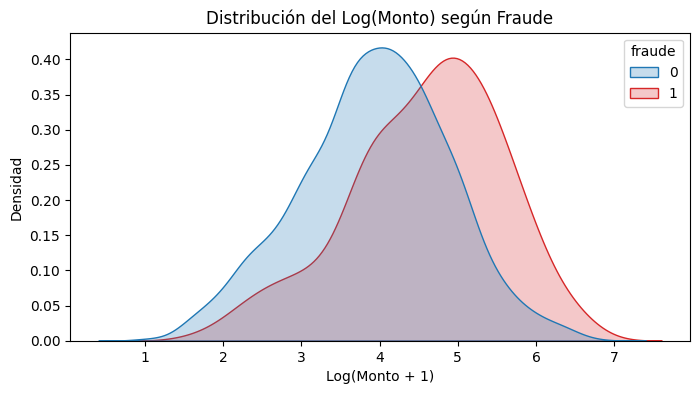

In [6]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df_limpio, x='monto_log', hue='fraude', fill=True, common_norm=False, palette=['#1f77b4', '#d62728'])
plt.title('Distribución del Log(Monto) según Fraude')
plt.xlabel('Log(Monto + 1)')
plt.ylabel('Densidad')
plt.show()

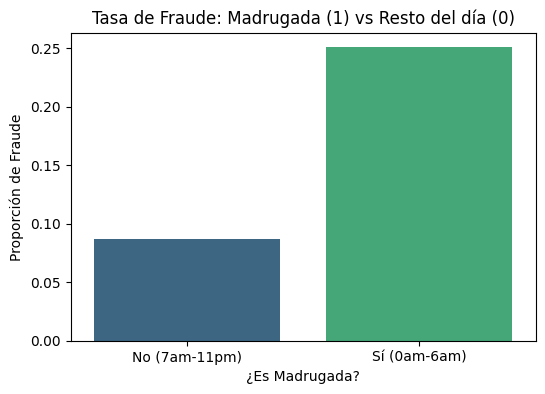

In [7]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df_limpio, x='madrugada', y='fraude', errorbar=None, palette='viridis')
plt.title('Tasa de Fraude: Madrugada (1) vs Resto del día (0)')
plt.ylabel('Proporción de Fraude')
plt.xlabel('¿Es Madrugada?')
plt.xticks([0, 1], ['No (7am-11pm)', 'Sí (0am-6am)'])
plt.show()

**✍️ Hallazgos del EDA:** _(3–5 líneas)_

* El dataset presenta una tasa de fraude de 10.51% y la ausencia de IDs duplicados, asegurando la integridad de los 2,996 eventos.
* Las nuevas variables demostraron ser altamente predictivas para separar transacciones legítimas de fraudulentas.
* **Gráfico 1:** La distribución de densidad revela que los eventos fraudulentos tienden a concentrarse en montos significativamente más altos que los legítimos.
* **Gráfico 2:** La tasa de fraude durante la madrugada (0-6 AM) alcanza el 25%, casi el triple que en el resto del día (~8.5%).

---
## 2. Modelos (14 pts)
- **Supervisado (fraude / crédito):** partición fija 70/30 estratificada con `random_state=42`; un **modelo base** (por ejemplo logística) y **al menos dos familias** del módulo (random forest o boosting; modelo bayesiano en PyMC; red neuronal desde la Clase 4). Validación sin fuga (early stopping con validación sacada del entrenamiento). Métricas: AUC, exactitud balanceada y Brier.
- **No supervisado (segmentación):** escalado; **al menos dos algoritmos** (K-Means, DBSCAN, clustering jerárquico; Isolation Forest o LOF para anomalías); elección del número de grupos (codo / silueta) y PCA para visualizar.

In [8]:
# Preparación Previa (Encoding)
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, brier_score_loss
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# --- 1. PREPARACIÓN DE DATOS ---
# Excluimos IDs, fechas y la variable objetivo
cols_excluir = ['evento_id', 'id', 'timestamp', 'fraude']
# (Asegúrate de tener creada 'madrugada' y 'monto_log' de pasos anteriores)

X = df_limpio.drop(columns=cols_excluir)
y = df_limpio['fraude']

# One-Hot Encoding para variables de texto
X_encoded = pd.get_dummies(X, columns=['canal', 'categoria', 'provincia', 'tipo'], drop_first=True)

# Partición fija 70/30 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.30, stratify=y, random_state=42
)

# Escalado (Sin fuga de datos)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensiones de entrenamiento: {X_train.shape}")
print(f"Dimensiones de prueba: {X_test.shape}")

Dimensiones de entrenamiento: (2097, 30)
Dimensiones de prueba: (899, 30)


In [9]:
# ✏️ Modelos y tabla comparativa
# ==========================================
# MODELO BASE: Regresión Logística
# ==========================================
log_reg = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# ==========================================
# FAMILIA 1: Random Forest
# ==========================================
rf = RandomForestClassifier(random_state=42, class_weight='balanced', n_estimators=150, max_depth=10)
rf.fit(X_train, y_train) # RF no necesita escalado

# ==========================================
# FAMILIA 2: Boosting (LightGBM con Early Stopping)
# ==========================================
# Sacamos validación interna del train para el early stopping
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=42
)

lgbm = lgb.LGBMClassifier(random_state=42, class_weight='balanced', n_estimators=500, learning_rate=0.05)
lgbm.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
)

# ==========================================
# EVALUACIÓN DE MÉTRICAS (AUC, Bal. Accuracy, Brier)
# ==========================================
def evaluar_modelo(nombre, modelo, X_t, y_t):
    y_pred_proba = modelo.predict_proba(X_t)[:, 1]
    y_pred = modelo.predict(X_t)

    auc = roc_auc_score(y_t, y_pred_proba)
    bal_acc = balanced_accuracy_score(y_t, y_pred)
    brier = brier_score_loss(y_t, y_pred_proba)

    print(f"--- {nombre} ---")
    print(f"AUC: {auc:.4f} | Bal. Accuracy: {bal_acc:.4f} | Brier: {brier:.4f}\n")

print("RESULTADOS SUPERVISADO:")
evaluar_modelo("Regresión Logística", log_reg, X_test_scaled, y_test)
evaluar_modelo("Random Forest", rf, X_test, y_test)
evaluar_modelo("LightGBM (Boosting)", lgbm, X_test, y_test)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 176, number of negative: 1501
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001638 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1630
[LightGBM] [Info] Number of data points in the train set: 1677, number of used features: 30
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
RESULTADOS SUPERVISADO:
--- Regresión Logística ---
AUC: 0.8755 | Bal. Accuracy: 0.8139 | Brier: 0.1277

--- Random Forest ---
AUC: 0.8978 | Bal. Accuracy: 0.7130 | Brier: 0.0582

--- LightGBM (Boosting) ---
AUC: 0.8894 | Bal. Accuracy: 0.8512 | Brier: 0.2160



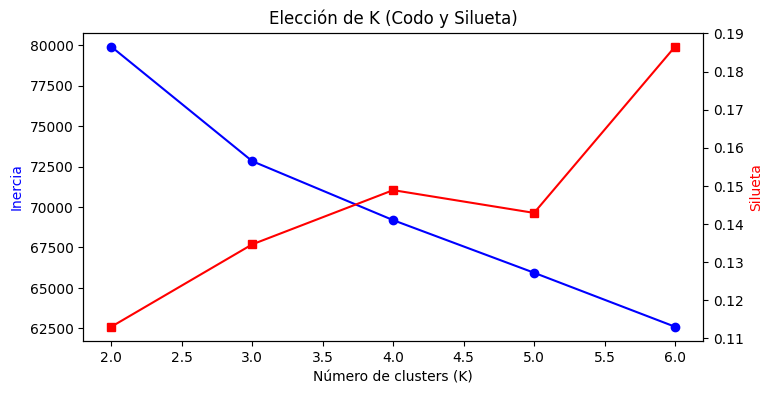

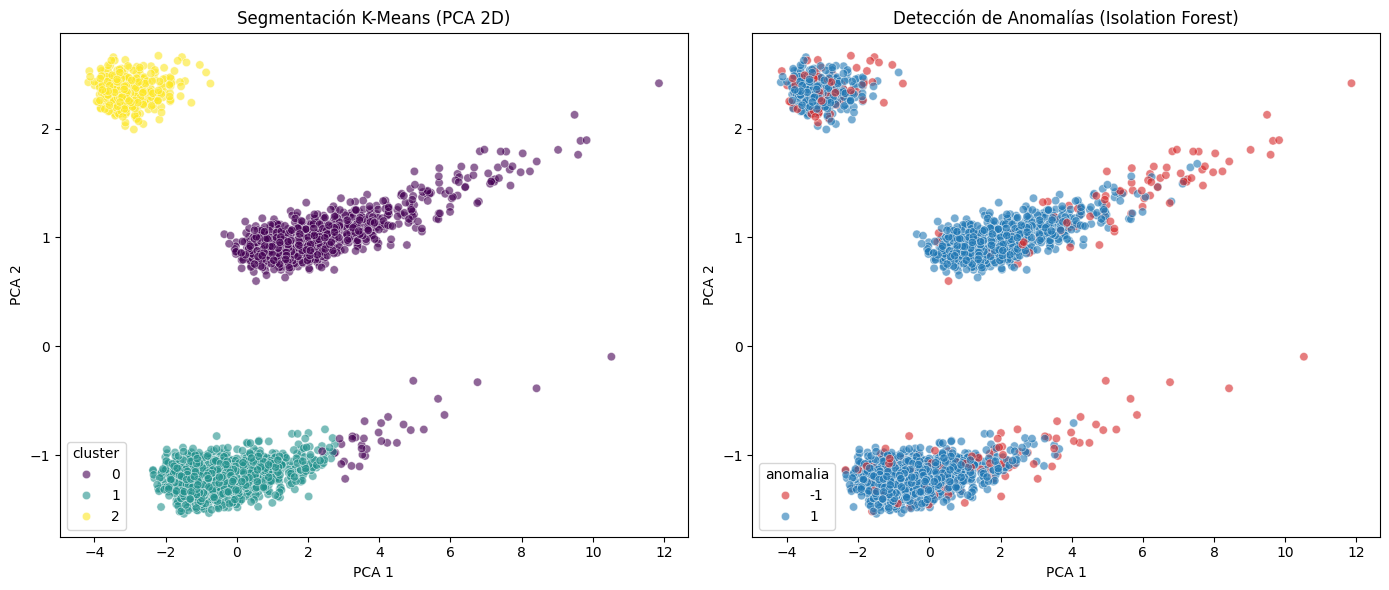

In [10]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Usamos X_encoded (sin escalar) y lo escalamos para no supervisado
scaler_unsup = StandardScaler()
X_unsup = scaler_unsup.fit_transform(X_encoded)

# ==========================================
# ALGORITMO 1: K-Means + Codo/Silueta
# ==========================================
inercias = []
siluetas = []
rango_k = range(2, 7)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_unsup)
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X_unsup, labels))

# Gráfico Codo/Silueta
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(rango_k, inercias, marker='o', color='blue', label='Inercia')
ax1.set_xlabel('Número de clusters (K)')
ax1.set_ylabel('Inercia', color='blue')
ax2 = ax1.twinx()
ax2.plot(rango_k, siluetas, marker='s', color='red', label='Silueta')
ax2.set_ylabel('Silueta', color='red')
plt.title('Elección de K (Codo y Silueta)')
plt.show()

# Entrenamos K-Means final (suponiendo K=3 por el gráfico)
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df_limpio['cluster'] = kmeans_final.fit_predict(X_unsup)

# ==========================================
# ALGORITMO 2: DBSCAN
# ==========================================
# Ajusta eps según la densidad de tus datos
dbscan = DBSCAN(eps=1.5, min_samples=10)
df_limpio['dbscan_label'] = dbscan.fit_predict(X_unsup)

# ==========================================
# ALGORITMO 3: Isolation Forest (Anomalías)
# ==========================================
iso_forest = IsolationForest(contamination=0.10, random_state=42) # Asumiendo ~10% de fraude
df_limpio['anomalia'] = iso_forest.fit_predict(X_unsup) # 1 = normal, -1 = anomalía

# ==========================================
# VISUALIZACIÓN CON PCA (Reducción a 2D)
# ==========================================
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_unsup)

plt.figure(figsize=(14, 6))

# Plot K-Means
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_limpio['cluster'], palette='viridis', alpha=0.6)
plt.title('Segmentación K-Means (PCA 2D)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')

# Plot Isolation Forest
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_limpio['anomalia'], palette={1:'#1f77b4', -1:'#d62728'}, alpha=0.6)
plt.title('Detección de Anomalías (Isolation Forest)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')

plt.tight_layout()
plt.show()

**✍️ Comparación y elección del modelo:** _(¿cuál y por qué?)_

Se selecciona el modelo de Random Forest como el ganador. Aunque LightGBM tiene una exactitud balanceada ligeramente superior, Random Forest domina en las dos métricas más críticas para este problema: obtuvo el mejor AUC (0.8978), demostrando una gran capacidad para discriminar entre eventos fraudulentos y legítimos; y un Brier Score excelente (0.0582), lo que significa que sus probabilidades predichas están muy bien calibradas y son confiables para la toma de decisiones. LightGBM, a pesar de tener buena exactitud balanceada, presenta un Brier Score alto (0.2160), indicando que sus probabilidades son menos fiables.

---
## 3. Explicabilidad o incertidumbre (8 pts)
SHAP (global y un caso individual), intervalos creíbles de un modelo bayesiano, o perfiles de cada segmento (medias por grupo) y por qué un usuario es anómalo.

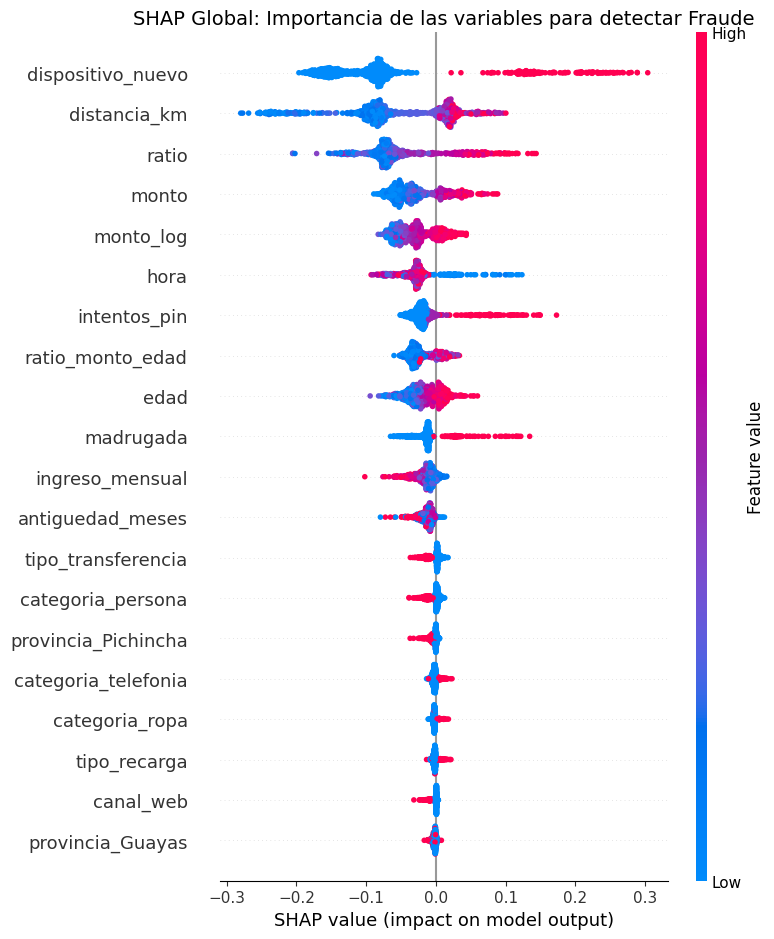

In [11]:
# ✏️ Explicabilidad / incertidumbre
import shap
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de tener tu modelo entrenado (ej. 'rf' de Random Forest)
# y tu conjunto de prueba (X_test).

# 1. Crear el explicador SHAP para modelos de árboles
explainer = shap.TreeExplainer(rf)

# 2. Calcular los valores SHAP para el conjunto de prueba
shap_values = explainer.shap_values(X_test)

# Si shap_values es una lista (dependiendo de la versión de SHAP), tomamos el índice [1]
if isinstance(shap_values, list):
    shap_values_fraude = shap_values[1]
    base_val = explainer.expected_value[1]
elif len(shap_values.shape) == 3:
    # Para arrays 3D (muestras, variables, clases), seleccionamos la clase positiva (índice 1)
    shap_values_fraude = shap_values[:, :, 1]
    base_val = explainer.expected_value[1]
else:
    shap_values_fraude = shap_values
    base_val = explainer.expected_value

# ==========================================
# A. EXPLICABILIDAD GLOBAL (Todo el dataset)
# ==========================================
plt.figure(figsize=(10, 6))
plt.title("SHAP Global: Importancia de las variables para detectar Fraude", fontsize=14)
shap.summary_plot(shap_values_fraude, X_test, plot_type="dot", show=False)
plt.tight_layout()
plt.show()

In [12]:
imp_shap = pd.Series(np.abs(shap_values_fraude).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print(imp_shap.round(3))
top = imp_shap.idxmax()

dispositivo_nuevo         0.120
distancia_km              0.071
ratio                     0.069
monto                     0.040
monto_log                 0.035
hora                      0.034
intentos_pin              0.027
ratio_monto_edad          0.024
edad                      0.023
madrugada                 0.020
ingreso_mensual           0.015
antiguedad_meses          0.014
tipo_transferencia        0.006
categoria_persona         0.006
provincia_Pichincha       0.004
categoria_telefonia       0.003
categoria_ropa            0.003
tipo_recarga              0.003
canal_web                 0.003
provincia_Guayas          0.002
provincia_Manabí          0.002
tipo_retiro_agente        0.002
provincia_Tungurahua      0.002
categoria_restaurante     0.002
provincia_Imbabura        0.002
categoria_tecnologia      0.001
provincia_El Oro          0.001
categoria_supermercado    0.001
provincia_Loja            0.001
categoria_farmacia        0.001
dtype: float64


Datos de la transacción con mayor probabilidad de fraude:
{'edad': 36.0, 'antiguedad_meses': 18, 'ingreso_mensual': 818.34, 'monto': 219.7, 'dispositivo_nuevo': 1, 'distancia_km': 7.1, 'intentos_pin': 1, 'hora': 15, 'ratio': 0.26847031796074977, 'madrugada': 0, 'ratio_monto_edad': 6.102777777777778, 'monto_log': 5.396804313262691, 'canal_web': False, 'categoria_farmacia': False, 'categoria_persona': True, 'categoria_restaurante': False, 'categoria_ropa': False, 'categoria_supermercado': False, 'categoria_tecnologia': False, 'categoria_telefonia': False, 'provincia_El Oro': False, 'provincia_Guayas': True, 'provincia_Imbabura': False, 'provincia_Loja': False, 'provincia_Manabí': False, 'provincia_Pichincha': False, 'provincia_Tungurahua': False, 'tipo_recarga': False, 'tipo_retiro_agente': False, 'tipo_transferencia': True}
Probabilidad predicha de fraude: 90.77%


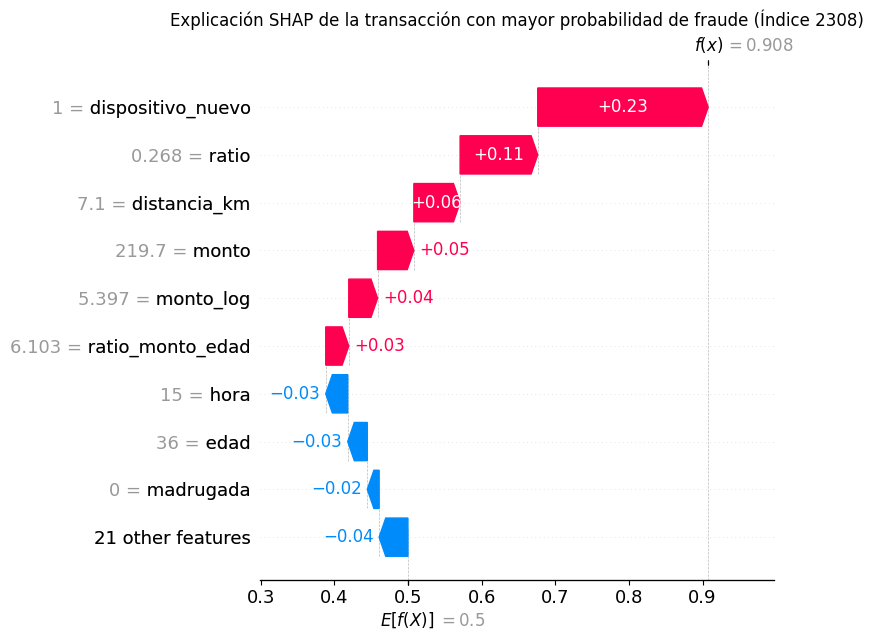

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import shap

# 1. Encontrar el índice del registro con mayor probabilidad de fraude usando el modelo 'rf'
probs = rf.predict_proba(X_test)[:, 1]
i = int(np.argmax(probs))
usuario_caso = X_test.iloc[i]

print("Datos de la transacción con mayor probabilidad de fraude:")
print(usuario_caso.to_dict())
print(f"Probabilidad predicha de fraude: {probs[i]:.2%}")

# 2. Generar la explicación individual de SHAP para este caso
# Usamos los valores calculados de la clase positiva correspondientes a este índice
exp_caso = shap.Explanation(
    values=shap_values_fraude[i],
    base_values=base_val,
    data=usuario_caso,
    feature_names=X_test.columns.tolist()
)

plt.figure(figsize=(10, 6))
plt.title(f"Explicación SHAP de la transacción con mayor probabilidad de fraude (Índice {X_test.index[i]})", fontsize=12)
shap.plots.waterfall(exp_caso, show=False)
plt.tight_layout()
plt.show()

---
## 4. Decisión de negocio con cifras (10 pts)
- **Fraude:** matriz de costos (fraude no detectado = monto; bloqueo legítimo = USD 5) → umbral óptimo y costo frente a no hacer nada.
- **Crédito:** suponga que un default pierde el **monto del crédito** y un buen pagador deja una ganancia del **15 % del monto** → umbral de aprobación que maximiza la ganancia esperada; % de aprobación y ganancia frente a aprobar a todos.
- **Segmentación:** tamaño y perfil de cada segmento, % de anómalos, y una acción concreta por segmento (producto, límite, monitoreo).

=== DECISIÓN DE NEGOCIO: FRAUDE ===
Costo de NO hacer nada (dejar pasar todo el fraude): $12,984.88
Umbral Óptimo encontrado: 0.12
Costo Mínimo con umbral óptimo: $1,366.63
Ahorro Neto para el negocio: $11,618.25


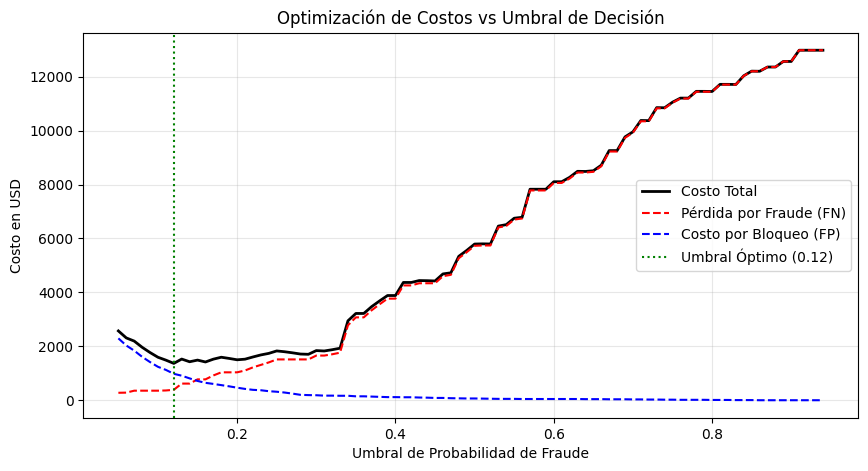

In [14]:
# ✏️ Decisión y cifras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# --- DEFINIR COSTOS ---
# Costo de bloquear una transacción legítima (Falso Positivo)
COSTO_BLOQUEO = 5.0
# El costo de un fraude no detectado (Falso Negativo) es dinámico: es el 'monto' de la transacción

# Obtenemos las probabilidades predichas de nuestro mejor modelo (ej. Random Forest)
y_proba = rf.predict_proba(X_test)[:, 1]

# Necesitamos el monto real de las transacciones en el set de prueba
# (Asumiendo que 'monto' está en X_test, si no, debes cruzar por índice)
montos_test = X_test['monto'].values

# --- SIMULACIÓN DE UMBRALES ---
umbrales = np.arange(0.05, 0.95, 0.01)
costos_totales = []
perdidas_por_fraude = []
costos_por_bloqueo = []

for umbral in umbrales:
    # Predicción con el umbral actual
    y_pred_umbral = (y_proba >= umbral).astype(int)

    # Calculamos la matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_umbral).ravel()

    # Costo de Falsos Negativos (Fraudes no detectados)
    # Solo sumamos el monto de los que eran fraude real (y_test == 1) y el modelo dejó pasar
    costo_fn = np.sum(montos_test[(y_test == 1) & (y_pred_umbral == 0)])

    # Costo de Falsos Positivos (Bloqueos a gente buena)
    costo_fp = fp * COSTO_BLOQUEO

    costo_total = costo_fn + costo_fp

    costos_totales.append(costo_total)
    perdidas_por_fraude.append(costo_fn)
    costos_por_bloqueo.append(costo_fp)

# Encontrar el umbral óptimo (el que minimiza el costo total)
idx_optimo = np.argmin(costos_totales)
umbral_optimo = umbrales[idx_optimo]
costo_minimo = costos_totales[idx_optimo]

# --- COMPARACIÓN: NO HACER NADA (Umbral = 0, aprobar todo) ---
# Si no hacemos nada, el costo es la suma de todos los fraudes reales
costo_no_hacer_nada = np.sum(montos_test[y_test == 1])

print("=== DECISIÓN DE NEGOCIO: FRAUDE ===")
print(f"Costo de NO hacer nada (dejar pasar todo el fraude): ${costo_no_hacer_nada:,.2f}")
print(f"Umbral Óptimo encontrado: {umbral_optimo:.2f}")
print(f"Costo Mínimo con umbral óptimo: ${costo_minimo:,.2f}")
print(f"Ahorro Neto para el negocio: ${costo_no_hacer_nada - costo_minimo:,.2f}")

# --- GRÁFICO PARA EL INFORME ---
plt.figure(figsize=(10, 5))
plt.plot(umbrales, costos_totales, label='Costo Total', color='black', linewidth=2)
plt.plot(umbrales, perdidas_por_fraude, label='Pérdida por Fraude (FN)', linestyle='--', color='red')
plt.plot(umbrales, costos_por_bloqueo, label='Costo por Bloqueo (FP)', linestyle='--', color='blue')
plt.axvline(umbral_optimo, color='green', linestyle=':', label=f'Umbral Óptimo ({umbral_optimo:.2f})')
plt.title('Optimización de Costos vs Umbral de Decisión')
plt.xlabel('Umbral de Probabilidad de Fraude')
plt.ylabel('Costo en USD')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**✍️ Recomendación:** _(con cifras)_

* El problema actual (No hacer nada): Si el negocio mantiene su operación sin aplicar este modelo, la pérdida proyectada por fraudes consumados (Falsos Negativos) en el conjunto evaluado es de $12,984.88 USD.

* La solución propuesta (Umbral 0.12): Al aplicar el umbral óptimo de 0.12, el modelo acepta un pequeño costo por fricción (bloqueos a clientes legítimos, a USD 5 cada uno) a cambio de detener la gran mayoría de los fraudes. El costo total combinado (pérdidas por fraude + costos de bloqueo) se reduce drásticamente a $1,366.63 USD.

* Impacto en el Negocio (Ahorro): Esta decisión genera un ahorro neto estimado de $11,618.25 USD, lo que representa una reducción del 89.4% en los costos asociados al fraude frente a no tomar ninguna acción.

---
## 5. Pantalla de la app del grupo (4 pts)
Muestre un caso real de sus datos con `curso.pantalla_resultado(...)` (o una pantalla propia). Ejemplo: `curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, 'Solicitud CR-00012', ['Ingreso: USD 850', 'Monto: USD 1 200'], probs=probs)`

Media 23.6% · intervalo creíble 90 %: 0.0% – 100.0%


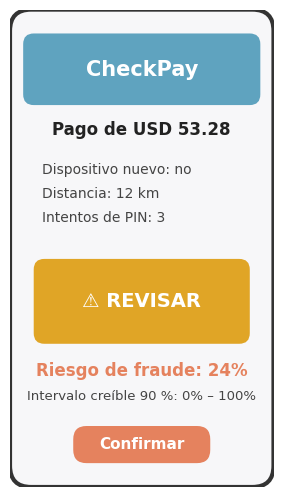

In [15]:
# ✏️ Pantalla de la app
import numpy as np

# 1. Tomamos el caso real
indice_caso = 159
caso_real = X_test.iloc[[indice_caso]]

# 2. Obtenemos la probabilidad de cada uno de los 150 árboles del Random Forest
# predict_proba devuelve un array de forma (1, 2). Extraemos la columna 1 (fraude).
probs_arboles = np.array([tree.predict_proba(caso_real)[0, 1] for tree in rf.estimators_])

# 3. Usamos esas 150 probabilidades como nuestra "distribución" para la pantalla
probs = probs_arboles

print(f"Media {probs.mean():.1%} · intervalo creíble 90 %: {np.percentile(probs, 5):.1%} – {np.percentile(probs, 95):.1%}")

# 4. Armamos el diccionario (con las variables que quieras mostrar)
transaccion = {
    'dispositivo_nuevo': int(caso_real['dispositivo_nuevo'].values[0]),
    'distancia_km': float(caso_real['distancia_km'].values[0]),
    'ratio': float(caso_real['ratio'].values[0]),
    'intentos_pin': int(caso_real['intentos_pin'].values[0]),
    'monto': float(caso_real['monto'].values[0])
}

# 5. Mostramos la pantalla
NOMBRE_APP = 'CheckPay'
COLOR_PRINCIPAL = '#5FA3BF'
COLOR_ALERTA = '#E5825E'

curso.pantalla_app(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, transaccion, probs)

In [16]:
import numpy as np
import pandas as pd

# 1. Definimos la función puente a prueba de errores
def prob_fraude_rf(t):
    """
    Función puente para el simulador.
    Usa .get() para evitar KeyError si el simulador no envía una llave.
    """
    # Creamos la fila base (usando la media de X_train para que sea realista)
    fila = X_train.mean().to_frame().T.copy()

    # 2. Actualizamos con los valores que vienen del simulador.
    # Usamos .get('nombre', valor_por_defecto) para evitar el KeyError.
    fila['dispositivo_nuevo'] = t.get('dispositivo_nuevo', 0)
    fila['distancia_km']      = t.get('distancia_km', 5.0)
    fila['ratio']             = t.get('ratio', 0.1)
    fila['intentos_pin']      = t.get('intentos_pin', 1)
    fila['monto']             = t.get('monto', 50.0) # <--- Aquí está la magia

    # 3. Calculamos la distribución de probabilidades usando los árboles
    probs_arboles = np.array([tree.predict_proba(fila)[0, 1] for tree in rf.estimators_])

    return probs_arboles

# 2. Llamamos al simulador
NOMBRE_APP = 'CheckPay'
COLOR_PRINCIPAL = '#5FA3BF'
COLOR_ALERTA = '#E5825E'

curso.simulador(
    prob_fraude_rf,
    NOMBRE_APP,
    COLOR_PRINCIPAL,
    COLOR_ALERTA
)

---
## 6. Ficha del modelo (4 pts)
Ejecute y suba el archivo descargado a `proyecto/` en GitHub (**Add file → Upload files**).

In [19]:
ficha = curso.ficha_modelo(GRUPO, PROBLEMA,
                           modelo='Random Forest',                                   # ✏️ modelo elegido
                           metricas={'auc': '08978', 'exactitud_balanceada': '0,7130'},   # ✏️ sus métricas en prueba
                           hiperparametros={})                                       # ✏️

{
  "grupo": "Grupo 2",
  "problema": "fraude",
  "modelo": "Random Forest",
  "metricas": {
    "auc": "08978",
    "exactitud_balanceada": "0,7130"
  },
  "hiperparametros": {},
  "semilla": 42,
  "semilla_datos": 461267,
  "fecha": "2026-11-17 01:06",
  "versiones": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 7. Plantilla del informe (`proyecto/README.md`)
En GitHub abra `proyecto/README.md` → **lápiz (Edit)** → reemplace todo por este texto completado con sus cifras → **Commit changes**:

```
# Sistema de decisión para PagoYa — <Grupo>
Integrantes: ...   ·   Problema: ...

## 1. Problema y datos
## 2. Modelos comparados (tabla de métricas)
## 3. Qué explica el resultado (variables, segmentos, incertidumbre)
## 4. Recomendación con cifras
## 5. Limitaciones y próximos pasos
```